In [1]:
!pip install streamlit


[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np

In [3]:
df = pd.read_csv('dataset_estudiantes_balanceado.csv')

In [4]:
df.head()

,Tareas,Examenes,Asistencia,Estudio_Horas,Sueno_Horas,Extracurriculares,Calificacion_Final,Aprobado
0,56.217808,33.514805,85.495792,23.999532,5.703021,1,79.671652,1
1,96.550001,42.287227,41.475215,18.962692,4.358559,1,82.650731,1
2,81.239576,34.160839,41.327413,10.124782,6.048144,0,60.380195,0
3,71.906094,27.096203,59.416613,13.791209,5.556087,1,63.816827,0
4,40.921305,29.650870,69.806012,10.043174,7.385603,0,49.874904,0


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Tareas              600 non-null    float64
 1   Examenes            600 non-null    float64
 2   Asistencia          600 non-null    float64
 3   Estudio_Horas       600 non-null    float64
 4   Sueno_Horas         600 non-null    float64
 5   Extracurriculares   600 non-null    int64  
 6   Calificacion_Final  600 non-null    float64
 7   Aprobado            600 non-null    int64  
dtypes: float64(6), int64(2)
memory usage: 37.6 KB


In [6]:
cols_numericas = df.select_dtypes(include=[np.number]).columns
df[cols_numericas] = df[cols_numericas].fillna(df[cols_numericas].median())
print("Valores faltantes tratados con éxito.")

Valores faltantes tratados con éxito.


In [7]:
features_a_limpiar = [col for col in cols_numericas if col not in ['Aprobado', 'Calificacion_Final']]

for col in features_a_limpiar:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR
    df[col] = np.clip(df[col], limite_inferior, limite_superior)

print("Valores atípicos acotados correctamente mediante IQR.")

Valores atípicos acotados correctamente mediante IQR.


In [8]:
X = df.drop(columns=['Calificacion_Final', 'Aprobado'])
y = df['Aprobado']

In [9]:
print("Dimensiones de X (variables predictoras):", X.shape)
print("Dimensiones de y (variable objetivo):", y.shape)

Dimensiones de X (variables predictoras): (600, 6)
Dimensiones de y (variable objetivo): (600,)


In [10]:
from sklearn.model_selection import train_test_split

# Dividir el conjunto original X e y en 80% entrenamiento y 20% prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [11]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [12]:
from sklearn.neural_network import MLPClassifier

model = MLPClassifier(hidden_layer_sizes=(64, 32), activation='relu', solver='adam', alpha=0.0001, max_iter=500, random_state=42)
model.fit(X_train_scaled, y_train)
print("¡Modelo Perceptrón Multicapa (MLP) entrenado con éxito!")

¡Modelo Perceptrón Multicapa (MLP) entrenado con éxito!


In [13]:
y_pred = model.predict(X_test_scaled)

In [14]:
import joblib

# Guardar el modelo entrenado y el escalador en archivos .pkl
joblib.dump(model, 'modelo_estudiantes.pkl')
joblib.dump(scaler, 'scaler.pkl')

print("¡Modelo y escalador guardados exitosamente como 'modelo_estudiantes.pkl' y 'scaler.pkl'!")

¡Modelo y escalador guardados exitosamente como 'modelo_estudiantes.pkl' y 'scaler.pkl'!


--- RESULTADOS DE LA EVALUACIÓN (MLP) ---
 - Accuracy:  0.9750
 - Precision: 0.9672
 - Recall:    0.9833
 - F1-Score:  0.9752

Reporte de Clasificación:
               precision    recall  f1-score   support

Reprobado (0)       0.98      0.97      0.97        60
 Aprobado (1)       0.97      0.98      0.98        60

     accuracy                           0.97       120
    macro avg       0.98      0.97      0.97       120
 weighted avg       0.98      0.97      0.97       120



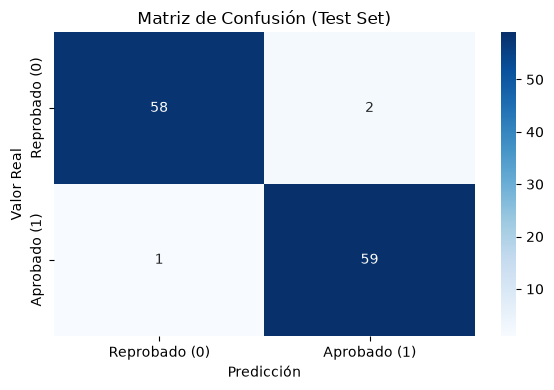

In [15]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

y_pred = model.predict(X_test_scaled)
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)

print("--- RESULTADOS DE LA EVALUACIÓN (MLP) ---")
print(f" - Accuracy:  {accuracy:.4f}")
print(f" - Precision: {precision:.4f}")
print(f" - Recall:    {recall:.4f}")
print(f" - F1-Score:  {f1:.4f}")
print("\nReporte de Clasificación:")
print(classification_report(y_test, y_pred, target_names=['Reprobado (0)', 'Aprobado (1)']))

# Visualización de la Matriz de Confusión
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Reprobado (0)', 'Aprobado (1)'],
            yticklabels=['Reprobado (0)', 'Aprobado (1)'])
plt.title("Matriz de Confusión (Test Set)")
plt.xlabel("Predicción")
plt.ylabel("Valor Real")
plt.tight_layout()
plt.show()